# **Makemore**

Makemore is a character level language model that uses a dataset of names with 32k name in it

Makemore is expected to make more words that are unique and sound like a name

It treats the name as sequences of insividual characters and knows how to predict the next character in the sequence 



In [1]:
words = open('names.txt','r').read().splitlines()

In [2]:
words [:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
len(words)

32033

In [4]:
min(len(w) for w in words)

2

In [8]:
if words: print(min(words, key=len))

an


In [5]:
max(len(w) for w in words)

15

In [9]:
if words: print(max(words, key=len))

muhammadibrahim


The model will be  trying to predict the next character in the sequence when given a concrete set of characters 

For example: Consider the name isabella 

* The character i is very likely to come at first in the sequence of a name 

* The character s is likely to come after s

* The character a is likey to come after is 

* The character b  is likey to come after isa

* After the characters isabella the word is likely to end 



### **Bigram Language Model**

The bigram language model always work with two characters at a time, By looking at the  single given character it will try to predict the next character in the sequence 

In [ ]:
for w in words[:1]:
    for ch1, ch2 in zip(w,w[1:]):
        print(ch1,ch2)


e m
m m
m a


The zip function in this code  zip(w,w[1:]) works by considering  

* w = emma
* w[1:] = mma

The zip takes two iterators and it pairs them up and create an iterator over the touples of their consecutive entries 

If any one of the list is shorter than the other then it will stop and return


| Index | `w` (The original) | `w[1:]` (The shifted one) | The Tuple produced by `zip` |
| :---: | :--- | :--- | :--- |
| **0** | `e` | `m` | `('e', 'm')` $\leftarrow$ 1st tuple |
| **1** | `m` | `m` | `('m', 'm')` $\leftarrow$ 2nd tuple |
| **2** | `m` | `a` | `('m', 'a')` $\leftarrow$ 3rd tuple |
| **3** | `a` | *None (End of string)* | *(Zip stops here)* |



In [21]:
w

'emma'

In [22]:
w[1:]

'mma'

In [23]:
list(w)

['e', 'm', 'm', 'a']

Now the result shows that e is  likely to come at first and a is likely to come at last, so to keep a track of it we halusinate a start and end character

In [25]:
for w in words[:1]:
    chs = ['<S>'] + list(w) + ['<E>']
    print(chs)
    for ch1, ch2 in zip(chs,chs[1:]):
        print(ch1,ch2)

['<S>', 'e', 'm', 'm', 'a', '<E>']
<S> e
e m
m m
m a
a <E>


In [26]:
for w in words[:3]:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        print(ch1,ch2)

<S> e
e m
m m
m a
a <E>
<S> o
o l
l i
i v
v i
i a
a <E>
<S> a
a v
v a
a <E>


In order to know the statistics about which character is likely to follow other charater the bigram language model will count  how often any one of these combinations occurs in the training set. 

so the next step is to make a dictionary that will keep a count of every bigrams 

In [27]:
b = {}
for w in words[:3]:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram = (ch1,ch2)
        b[bigram] = b.get(bigram, 0 ) + 1
        print(ch1,ch2)

<S> e
e m
m m
m a
a <E>
<S> o
o l
l i
i v
v i
i a
a <E>
<S> a
a v
v a
a <E>


In [28]:
b

{('<S>', 'e'): 1,
 ('e', 'm'): 1,
 ('m', 'm'): 1,
 ('m', 'a'): 1,
 ('a', '<E>'): 3,
 ('<S>', 'o'): 1,
 ('o', 'l'): 1,
 ('l', 'i'): 1,
 ('i', 'v'): 1,
 ('v', 'i'): 1,
 ('i', 'a'): 1,
 ('<S>', 'a'): 1,
 ('a', 'v'): 1,
 ('v', 'a'): 1}

now lets make the bigrams for all the words in the dataset

In [29]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram = (ch1,ch2)
        b[bigram] = b.get(bigram, 0 ) + 1
        

In [30]:
b

{('<S>', 'e'): 1531,
 ('e', 'm'): 769,
 ('m', 'm'): 168,
 ('m', 'a'): 2590,
 ('a', '<E>'): 6640,
 ('<S>', 'o'): 394,
 ('o', 'l'): 619,
 ('l', 'i'): 2480,
 ('i', 'v'): 269,
 ('v', 'i'): 911,
 ('i', 'a'): 2445,
 ('<S>', 'a'): 4410,
 ('a', 'v'): 834,
 ('v', 'a'): 642,
 ('<S>', 'i'): 591,
 ('i', 's'): 1316,
 ('s', 'a'): 1201,
 ('a', 'b'): 541,
 ('b', 'e'): 655,
 ('e', 'l'): 3248,
 ('l', 'l'): 1345,
 ('l', 'a'): 2623,
 ('<S>', 's'): 2055,
 ('s', 'o'): 531,
 ('o', 'p'): 95,
 ('p', 'h'): 204,
 ('h', 'i'): 729,
 ('<S>', 'c'): 1542,
 ('c', 'h'): 664,
 ('h', 'a'): 2244,
 ('a', 'r'): 3264,
 ('r', 'l'): 413,
 ('l', 'o'): 692,
 ('o', 't'): 118,
 ('t', 't'): 374,
 ('t', 'e'): 716,
 ('e', '<E>'): 3983,
 ('<S>', 'm'): 2538,
 ('m', 'i'): 1256,
 ('a', 'm'): 1634,
 ('m', 'e'): 818,
 ('<S>', 'h'): 874,
 ('r', 'p'): 14,
 ('p', 'e'): 197,
 ('e', 'r'): 1958,
 ('r', '<E>'): 1377,
 ('e', 'v'): 463,
 ('v', 'e'): 568,
 ('l', 'y'): 1588,
 ('y', 'n'): 1826,
 ('n', '<E>'): 6763,
 ('b', 'i'): 217,
 ('i', 'g'): 428,


In [31]:
# The least common bigrams can be found using b.items() which will return a tuple  and this is then sorted based on the second value which is the count 

sorted(b.items(), key = lambda kv: kv[1])

[(('q', 'r'), 1),
 (('d', 'z'), 1),
 (('p', 'j'), 1),
 (('q', 'l'), 1),
 (('p', 'f'), 1),
 (('q', 'e'), 1),
 (('b', 'c'), 1),
 (('c', 'd'), 1),
 (('m', 'f'), 1),
 (('p', 'n'), 1),
 (('w', 'b'), 1),
 (('p', 'c'), 1),
 (('h', 'p'), 1),
 (('f', 'h'), 1),
 (('b', 'j'), 1),
 (('f', 'g'), 1),
 (('z', 'g'), 1),
 (('c', 'p'), 1),
 (('p', 'k'), 1),
 (('p', 'm'), 1),
 (('x', 'n'), 1),
 (('s', 'q'), 1),
 (('k', 'f'), 1),
 (('m', 'k'), 1),
 (('x', 'h'), 1),
 (('g', 'f'), 1),
 (('v', 'b'), 1),
 (('j', 'p'), 1),
 (('g', 'z'), 1),
 (('v', 'd'), 1),
 (('d', 'b'), 1),
 (('v', 'h'), 1),
 (('h', 'h'), 1),
 (('g', 'v'), 1),
 (('d', 'q'), 1),
 (('x', 'b'), 1),
 (('w', 'z'), 1),
 (('h', 'q'), 1),
 (('j', 'b'), 1),
 (('x', 'm'), 1),
 (('w', 'g'), 1),
 (('t', 'b'), 1),
 (('z', 'x'), 1),
 (('p', 'b'), 2),
 (('t', 'g'), 2),
 (('q', 's'), 2),
 (('t', 'x'), 2),
 (('f', 'k'), 2),
 (('b', 't'), 2),
 (('j', 'n'), 2),
 (('k', 'c'), 2),
 (('z', 'k'), 2),
 (('s', 'j'), 2),
 (('s', 'f'), 2),
 (('z', 'j'), 2),
 (('n', 'q

In [32]:
# The most common occured bigrams 

sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

For convenience this python dictionary will be converted to a 2D array

The rows will be the first character and columns will be the second character 

each entry in the 2D array will tell how often the second character follows the first character in the dataset 

below is an example of the 2D array

| Row \ Col | `a` | `i` | `k` | `l` | `n` | `r` | `<E>` |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **`<S>`** | 4,410 | 0 | 2,963 | 0 | 0 | 0 | 0 |
| **`a`** | 0 | 0 | 0 | 0 | 5,438 | 3,264 | 6,640 |
| **`e`** | 0 | 0 | 0 | 3,248 | 0 | 0 | 3,983 |
| **`n`** | 2,977 | 0 | 0 | 0 | 0 | 0 | 6,763 |
| **`r`** | 0 | 3,033 | 0 | 0 | 0 | 0 | 0 |



This can be implimented using pytorch and an example of how arrays works on pytorch is given below

In [34]:
import torch 

In [35]:
# Create an array 3 rows and 5 columns using torch 

a = torch.zeros((3,5)) 
a

tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])

In [36]:
# Print the datatype of the array 

a.dtype

torch.float32

In [37]:
# The data type is  float 32. Because we are using counts we can change the data type to int 32
a = torch.zeros((3,5), dtype = torch.int32) 
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [38]:
# some examples on how to change the data inside the tensor 

a[1,3] = 1
a


tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [ ]:
a[1,3] += 1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 2, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [41]:
a[0,0] = 5
a

tensor([[5, 0, 0, 0, 0],
        [0, 0, 0, 2, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

The array we are interested in should be having a size of 28 x 28 

26 aplhabets + < S > , < E >

In [42]:
N = torch.zeros((28,28), dtype = torch.int32) 

In [47]:
w

'zzyzx'

In [45]:
set(''.join(w))

{'x', 'y', 'z'}

In [50]:
#  example for how set is constructed without any repeated values 
set("mariya")

{'a', 'i', 'm', 'r', 'y'}

next we can start making the array.

* In the previous code we were using characters which are strings and for this we need to use integers , hense some modifications are done on the code 

* Words contain all the names in the dataset, and these names are concatenated into a single massive string using .join()

* the next step will be to pass the long string into a set constructor which will have no repeated entries 

* Thi set will be converted into a sorted list 

In [51]:
chars = sorted(list(set(''.join(words))))

In [53]:
# Now we will map the character to the integer

# stoi = string to integer

stoi = {s:i for i,s in enumerate(chars)}

In [54]:
stoi

{'a': 0,
 'b': 1,
 'c': 2,
 'd': 3,
 'e': 4,
 'f': 5,
 'g': 6,
 'h': 7,
 'i': 8,
 'j': 9,
 'k': 10,
 'l': 11,
 'm': 12,
 'n': 13,
 'o': 14,
 'p': 15,
 'q': 16,
 'r': 17,
 's': 18,
 't': 19,
 'u': 20,
 'v': 21,
 'w': 22,
 'x': 23,
 'y': 24,
 'z': 25}

In [55]:
# no we specifically set the intgers for <S> and <E>

stoi['<S>'] = 26
stoi['<E>'] = 27

In [57]:
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1,ix2] += 1
        

In [58]:
N

tensor([[ 1112,  1082,   940,  2084,  1384,   268,   336,  4664,  3300,   350,
          1136,  5056,  3268, 10876,   126,   164,   120,  6528,  2236,  1374,
           762,  1668,   322,   364,  4100,   870,     0, 13280],
        [  642,    76,     2,   130,  1310,     0,     0,    82,   434,     2,
             0,   206,     0,     8,   210,     0,     0,  1684,    16,     4,
            90,     0,     0,     0,   166,     0,     0,   228],
        [ 1630,     0,    84,     2,  1102,     0,     4,  1328,   542,     6,
           632,   232,     0,     0,   760,     2,    22,   152,    10,    70,
            70,     0,     0,     6,   208,     8,     0,   194],
        [ 2606,     2,     6,   298,  2566,    10,    50,   236,  1348,    18,
             6,   120,    60,    62,   756,     0,     2,   848,    58,     8,
           184,    34,    46,     0,   634,     2,     0,  1032],
        [ 1358,   242,   306,   768,  2542,   164,   250,   304,  1636,   110,
           356,  6496,  1

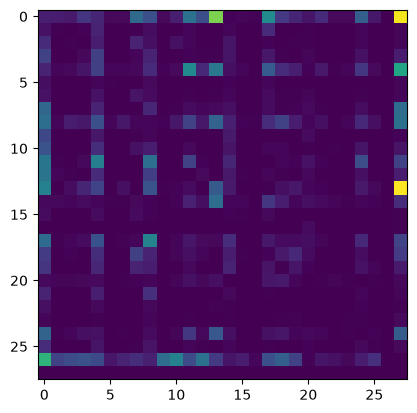

In [59]:
# The array can now be visualise for better understanding 

import matplotlib.pyplot as plt
%matplotlib inline 
plt.imshow(N)

In [60]:
# to make the visualisation better first invert the dictionary from stoi to itos 

itos = {i:s for s,i in stoi.items()}
itos

{0: 'a',
 1: 'b',
 2: 'c',
 3: 'd',
 4: 'e',
 5: 'f',
 6: 'g',
 7: 'h',
 8: 'i',
 9: 'j',
 10: 'k',
 11: 'l',
 12: 'm',
 13: 'n',
 14: 'o',
 15: 'p',
 16: 'q',
 17: 'r',
 18: 's',
 19: 't',
 20: 'u',
 21: 'v',
 22: 'w',
 23: 'x',
 24: 'y',
 25: 'z',
 26: '<S>',
 27: '<E>'}

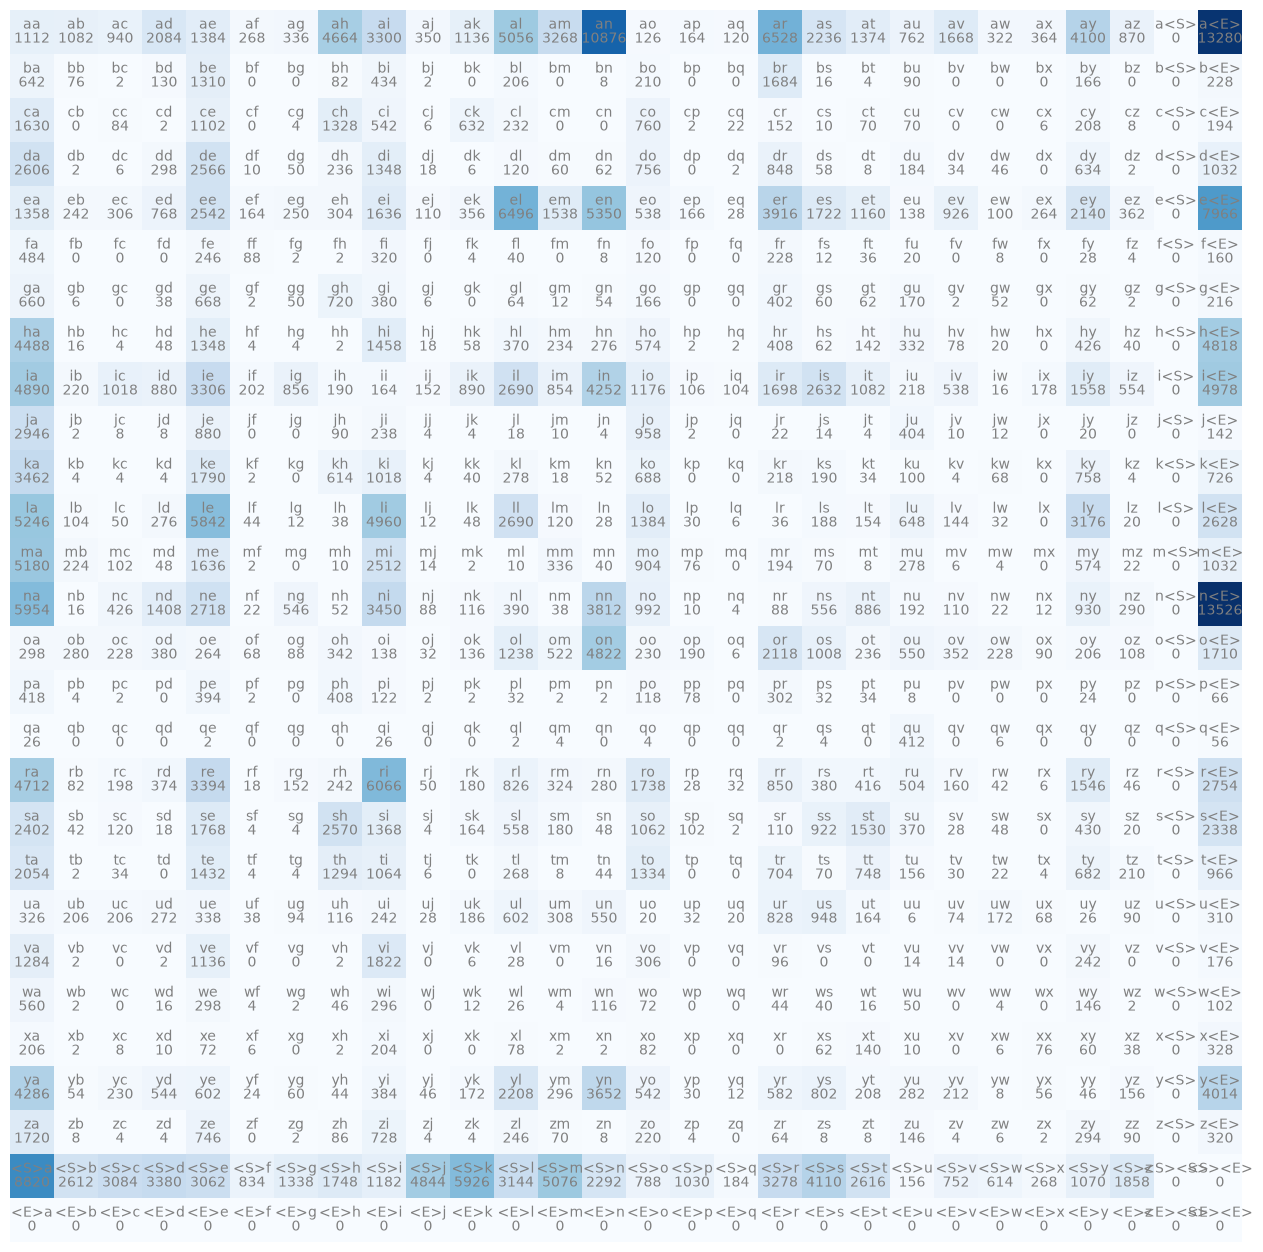

In [61]:
import matplotlib.pyplot as plt
%matplotlib inline 

plt.figure(figsize = (16,16))
plt.imshow(N, cmap = 'Blues')

for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center" , va="bottom", color = 'gray')
        plt.text(j, i, N[i, j].item(), ha = "center", va = "top", color='gray')

plt.axis('off');